In [2]:
print("Hello world")
var=21

Hello world


In [3]:
var

21

In [6]:
name=input("Enter your name: ")
age=int(input("Enter your age: "))
if age>=18:
    print(f"Hello {name} your age is above 18 and you are eligible to vote")
else:
    print("Sorry",name,"You are not eligible to vote")

Enter your name:  Ritika
Enter your age:  17


Sorry Ritika You are not eligible to vote


In [1]:
lis=list(range(10,14))
print(lis)

[10, 11, 12, 13]


In [1]:
name=input("Enter a name: ")
for i in name:
    print(i)

Enter a name:  Rishi Rastogiiiii


R
i
s
h
i
 
R
a
s
t
o
g
i
i
i
i
i


In [6]:
a=list(("ayushman","Barthwal"))
print(a)
b=list("Ayusman")
print(a[0])
print(a[0][1])

['ayushman', 'Barthwal']
ayushman
y


In [12]:
q="Ayushman"
a=list(q)
q=q.replace("a","A")
print(q)
print(a)

AyushmAn
['A', 'y', 'u', 's', 'h', 'm', 'a', 'n']


In [1]:
yo={10,20,30}
print(yo);
for i in yo:
    if 10 in yo:
        print(i)
        

{10, 20, 30}
10
20
30


First five rows of dataset:
          X         y
0  0.749080  6.334288
1  1.901429  9.405278
2  1.463988  8.483724
3  1.197317  5.604382
4  0.312037  4.716440

--- Linear Regression (One Variable) ---
Intercept: [4.14291332]
Coefficient: [[2.79932366]]


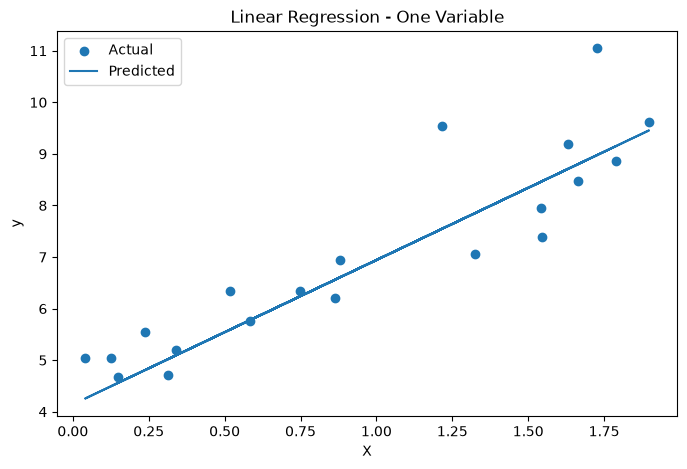


--- Linear Regression (Multiple Variables) ---
Intercept: 3.91498955836708
Coefficients: [3.05294884 1.962303   1.34302962]

--- Polynomial Regression ---
Intercept: [1.73625819]
Coefficients: [[0.         0.94285051 0.56726223]]


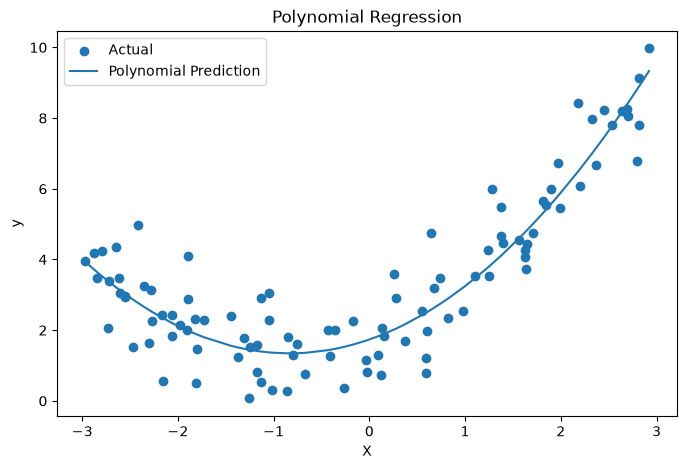


========== MODEL EVALUATION ==========
MSE (Linear Regression - One Variable): 0.6536995137170021
MSE (Linear Regression - Multiple Variables): 2.0173924806102996
MSE (Polynomial Regression): 0.6358406072820807


In [2]:
# Experiment 5: Supervised Learning - Regressions
# 1. Linear Regression with One Variable
# 2. Linear Regression with Multiple Variables
# 3. Polynomial Regression

# ==============================
# Step 1: Import Libraries
# ==============================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error


# ==============================
# Step 2: Linear Regression
# with One Variable
# ==============================

np.random.seed(42)

# Generate synthetic dataset
X = 2 * np.random.rand(100, 1)
y = 4 + 3 * X + np.random.randn(100, 1)

# Convert to DataFrame
data = pd.DataFrame(
    np.c_[X, y],
    columns=["X", "y"]
)

print("First five rows of dataset:")
print(data.head())


# ==============================
# Step 3: Train-Test Split
# ==============================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Create Linear Regression model
lin_reg = LinearRegression()

# Train model
lin_reg.fit(X_train, y_train)

# Predict
y_pred = lin_reg.predict(X_test)

# Display model parameters
print("\n--- Linear Regression (One Variable) ---")
print("Intercept:", lin_reg.intercept_)
print("Coefficient:", lin_reg.coef_)


# Plot regression line
plt.figure(figsize=(8, 5))
plt.scatter(X_test, y_test, label="Actual")
plt.plot(X_test, y_pred, label="Predicted")
plt.xlabel("X")
plt.ylabel("y")
plt.title("Linear Regression - One Variable")
plt.legend()
plt.show()


# ==============================
# Step 4: Linear Regression
# with Multiple Variables
# ==============================

np.random.seed(42)

# Generate dataset with 3 input variables
X_m = 2 * np.random.rand(100, 3)

y_m = (
    4
    + 3 * X_m[:, 0]
    + 2 * X_m[:, 1]
    + X_m[:, 2]
    + np.random.randn(100)
)

# Split dataset
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_m,
    y_m,
    test_size=0.2,
    random_state=42
)

# Create model
lin_reg_m = LinearRegression()

# Train model
lin_reg_m.fit(X_train_m, y_train_m)

# Predict
y_pred_m = lin_reg_m.predict(X_test_m)

# Display model parameters
print("\n--- Linear Regression (Multiple Variables) ---")
print("Intercept:", lin_reg_m.intercept_)
print("Coefficients:", lin_reg_m.coef_)


# ==============================
# Step 5: Polynomial Regression
# ==============================

np.random.seed(42)

# Generate polynomial dataset
X_poly = 6 * np.random.rand(100, 1) - 3

y_poly = (
    0.5 * X_poly**2
    + X_poly
    + 2
    + np.random.randn(100, 1)
)

# Create polynomial features
poly_features = PolynomialFeatures(degree=2)

X_poly_transformed = poly_features.fit_transform(X_poly)

# Split dataset
X_train_poly, X_test_poly, y_train_poly, y_test_poly = train_test_split(
    X_poly_transformed,
    y_poly,
    test_size=0.2,
    random_state=42
)

# Create Linear Regression model
lin_reg_poly = LinearRegression()

# Train model
lin_reg_poly.fit(X_train_poly, y_train_poly)

# Predict
y_pred_poly = lin_reg_poly.predict(X_test_poly)

print("\n--- Polynomial Regression ---")
print("Intercept:", lin_reg_poly.intercept_)
print("Coefficients:", lin_reg_poly.coef_)


# Plot polynomial regression
X_sorted = np.sort(X_poly, axis=0)
X_sorted_transformed = poly_features.transform(X_sorted)

y_sorted_pred = lin_reg_poly.predict(X_sorted_transformed)

plt.figure(figsize=(8, 5))
plt.scatter(X_poly, y_poly, label="Actual")
plt.plot(
    X_sorted,
    y_sorted_pred,
    label="Polynomial Prediction"
)
plt.xlabel("X")
plt.ylabel("y")
plt.title("Polynomial Regression")
plt.legend()
plt.show()


# ==============================
# Step 6: Model Evaluation
# ==============================

# Calculate Mean Squared Error
mse_lin = mean_squared_error(y_test, y_pred)

mse_lin_multi = mean_squared_error(
    y_test_m,
    y_pred_m
)

mse_poly = mean_squared_error(
    y_test_poly,
    y_pred_poly
)
AC
# Display results
print("\n========== MODEL EVALUATION ==========")

print("MSE (Linear Regression - One Variable):", mse_lin)

print(
    "MSE (Linear Regression - Multiple Variables):",
    mse_lin_multi
)

print(
    "MSE (Polynomial Regression):",
    mse_poly
)

In [5]:
def square(num):
    return num**2


print(square(2))

4


In [7]:
def is_even(num):
    if num%2==0:
        return True
    else:
        return False

bool=is_even(4)
print(bool)

True


In [8]:
def sum(a,b):
    return a+b

result=sum(5,4)
print(result)

9


In [10]:
def power(base,exponent=2):
    return base**exponent

print(power(5))
print(power(2,3))

25
8


In [11]:
def introduce(name, age, city):
    print(name, age, city)

introduce(city="Delhi",age=21,name="Rahul")

Rahul 21 Delhi


In [12]:
def add(*args):
    sum=0
    for i in args:
        sum+=i
    return sum

print(add(1,2,3,4))
        

10


In [13]:
def profile(*args,**kwargs):
    print(args)
    print(kwargs)
profile("Rahul", 21, city="Delhi", role="Developer")

('Rahul', 21)
{'city': 'Delhi', 'role': 'Developer'}


In [14]:
x = 10

def test():
    print(x)

test()
print(x)

10
10


In [15]:
x = 10

def outer():
    x = 20

    def inner():
        print(x)

    inner()

outer()

20
